In [1]:
!pip install ultralytics opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from google.colab import files

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("VisionPort model loaded successfully!")

VisionPort model loaded successfully!


In [4]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)

Saving traffic.jpg to traffic.jpg
Image uploaded: traffic.jpg


In [5]:
# Detect objects in the image
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Object detection completed!")


image 1/1 /content/traffic.jpg: 448x640 6 persons, 38 cars, 1 bus, 2 trucks, 381.3ms
Speed: 17.0ms preprocess, 381.3ms inference, 30.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict
Object detection completed!


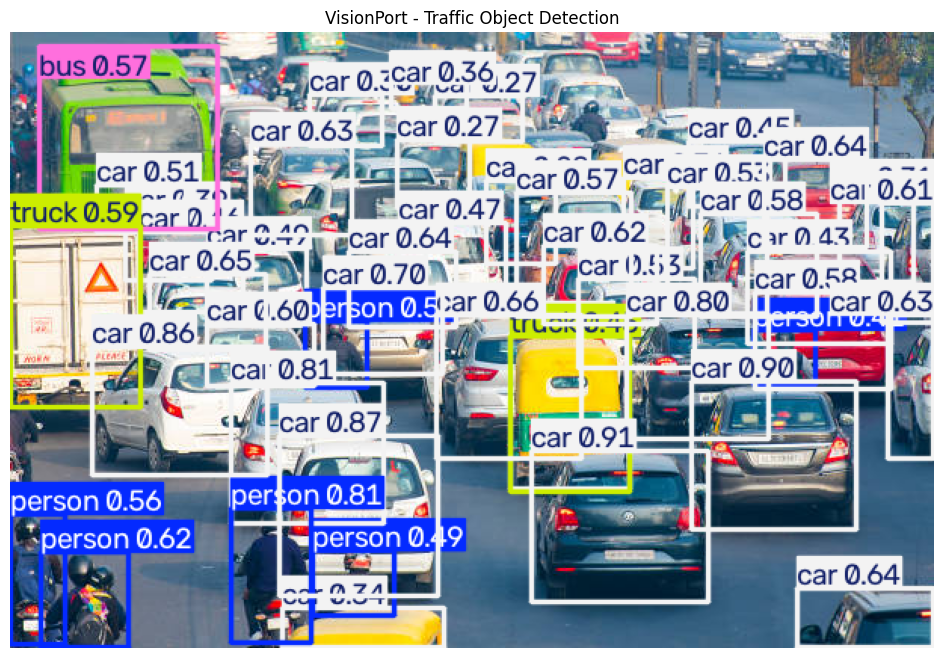

In [8]:
# Get image with bounding boxes
output_image = results[0].plot()

# Convert BGR to RGB
output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("VisionPort - Traffic Object Detection")
plt.show()

In [9]:
for box in results[0].boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    confidence = float(box.conf[0])

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

Object: car | Confidence: 90.76 %
Object: car | Confidence: 90.34 %
Object: car | Confidence: 87.38 %
Object: car | Confidence: 86.31 %
Object: person | Confidence: 80.94 %
Object: car | Confidence: 80.68 %
Object: car | Confidence: 79.82 %
Object: car | Confidence: 69.93 %
Object: car | Confidence: 66.49 %
Object: car | Confidence: 64.64 %
Object: car | Confidence: 64.47 %
Object: car | Confidence: 64.39 %
Object: car | Confidence: 64.28 %
Object: car | Confidence: 63.14 %
Object: car | Confidence: 62.66 %
Object: person | Confidence: 62.3 %
Object: car | Confidence: 62.17 %
Object: car | Confidence: 61.32 %
Object: car | Confidence: 60.06 %
Object: truck | Confidence: 59.24 %
Object: person | Confidence: 58.61 %
Object: car | Confidence: 58.48 %
Object: car | Confidence: 57.74 %
Object: bus | Confidence: 56.8 %
Object: car | Confidence: 56.58 %
Object: person | Confidence: 55.82 %
Object: car | Confidence: 53.35 %
Object: car | Confidence: 53.15 %
Object: car | Confidence: 50.59 %
Ob